In [47]:
#import libraries
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [48]:
# load data 
df = pd.read_csv("Mall_Customers.csv")
df.head()
# df.describe()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [49]:
X = df[['Age','Annual Income (k$)']]
Y =df['Spending Score (1-100)']

#Scalar
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)

optimal_k = 3
kmeans  = KMeans(n_clusters=optimal_k,init='k-means++',max_iter=300,n_init=10, random_state=0)
y_kmeans = kmeans.fit_predict(X_scaled)

df['Cluster'] = y_kmeans
print(df.groupby('Cluster').agg({"Age":'mean','Annual Income (k$)':'mean','Spending Score (1-100)': 'mean'}))

               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        55.806452           51.225806               39.677419
1        34.960526           85.934211               53.394737
2        26.661290           38.790323               56.806452


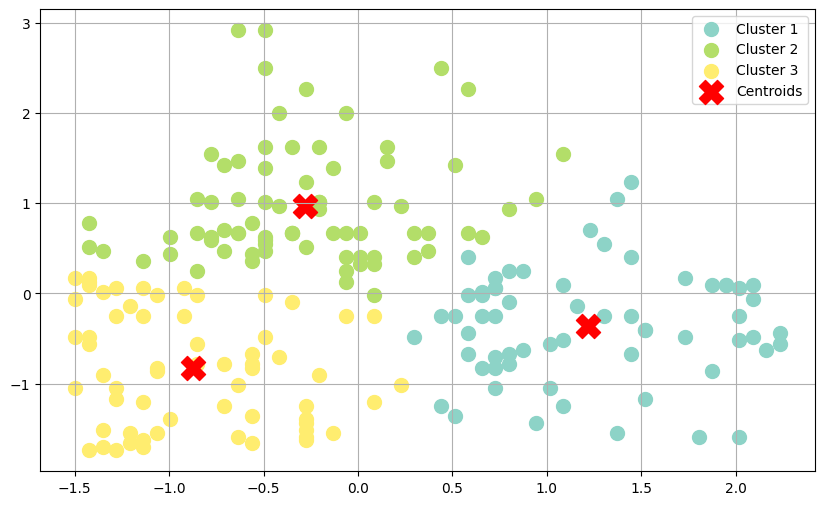

In [50]:
# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# KMeans on scaled data
kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    max_iter=300,
    n_init=10,
    random_state=0
)

y_kmeans = kmeans.fit_predict(X_scaled)

# Plot
fig, ax = plt.subplots(figsize=(10, 6))

colors = plt.cm.Set3(np.linspace(0, 1, optimal_k))

for i in range(optimal_k):
    ax.scatter(
        X_scaled[y_kmeans == i, 0],
        X_scaled[y_kmeans == i, 1],
        s=100,
        color=colors[i],
        label=f'Cluster {i+1}'
    )

ax.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    s=300,
    c='red',
    marker='X',
    label='Centroids'
)

ax.legend()
ax.grid(True)
plt.show()